# PINNs Framework — Demo: 1-D Viscous Burgers Equation

This notebook shows the full API of the `pinns_framework` package.

**PDE:**  
$$\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} = \nu\,\frac{\partial^2 u}{\partial x^2}, \quad x\in[-1,1],\; t\in[0,T]$$

**IC / BC (Raissi et al. benchmark):**  
$$u(0,x) = -\sin(\pi x), \qquad u(t,-1) = u(t,1) = 0$$

**Three independent switches — change one line each:**
| What | Option A | Option B |
|------|----------|----------|
| Architecture | `arch="MLP"` | `arch="KAN"` |
| Training scheme | `scheme="TD-PINNS"` | `scheme="VANILLA"` |
| Loss form | `form="strong"` | `form="weak"` *(future)* |

In [1]:
import sys
import os

# Notebook lives in dev_version/notebooks/ — go one level up to reach dev_version/
# which is the directory that contains the pinns_framework package.
sys.path.insert(0, os.path.dirname(os.getcwd()))

import numpy as np
import torch
import matplotlib.pyplot as plt

from pinns_framework import (
    PINArchitecture,
    PINSpatialDimension,
    PINLossFunction,
    PINTrainer,
)

torch.manual_seed(42)
print('torch:', torch.__version__)

torch: 2.10.0


## 1. Architecture

Pick `"MLP"` or `"KAN"` — everything downstream stays the same.

In [2]:
net = PINArchitecture(
    arch="KAN",
    params_arch={"layers": (1, 16, 1), "grid_size": 5, "spline_order": 3},
)

print(net)

checkpoint directory created: ./model
saving model version 0.0
KANNet(
  (net): MultKAN(
    (act_fun): ModuleList(
      (0-1): 2 x KANLayer(
        (base_fun): SiLU()
      )
    )
    (base_fun): SiLU()
    (symbolic_fun): ModuleList(
      (0-1): 2 x Symbolic_KANLayer()
    )
  )
)


In [3]:
"""
# ── MLP (no extra install needed) ─────────────────────────────────────────────
net = PINArchitecture(
    arch="MLP",
    params_arch={"layers": (1, 64, 64, 64, 1), "activation": "tanh"},
)

# ── KAN (install first: pip install pykan)
# net = PINArchitecture(
#     arch="KAN",
#     params_arch={"layers": (1, 16, 16, 1), "grid_size": 5, "spline_order": 3},
# )
"""
print(net)

KANNet(
  (net): MultKAN(
    (act_fun): ModuleList(
      (0-1): 2 x KANLayer(
        (base_fun): SiLU()
      )
    )
    (base_fun): SiLU()
    (symbolic_fun): ModuleList(
      (0-1): 2 x Symbolic_KANLayer()
    )
  )
)


## 2. Spatial Dimension

`PINSpatialDimension` describes the physical domain and controls
how many interior collocation points are sampled per training step.

In [4]:
x_dim = PINSpatialDimension(name="x", domain=(-1.0, 1.0), n_colloc=200)
print(x_dim)

PINSpatialDimension(name='x', domain=(-1.0, 1.0), n_colloc=200)


## 3. PDE Residual Function

Write the PDE in strong form as a plain Python function.  
The trainer calls it with the right keyword arguments depending on the scheme.

**TD-PINNs (Backward Euler) signature:**
```python
residual_fn(u, u_prev, x, dt, **pde_kwargs)
```
- `u`      — current network output at collocation points  
- `u_prev` — previous-step output (already detached, no grad through it)  
- `x`      — collocation tensor with `requires_grad=True` — use for `autograd.grad`  
- `dt`     — time step size  

**Vanilla PINNs signature:**
```python
residual_fn(u, t, x, **pde_kwargs)
```
- `u` — network output `u(t, x)`  
- `t` — time collocation points with `requires_grad=True`  
- `x` — spatial collocation points with `requires_grad=True`  

In [5]:
# ── TD-PINNs residual (Backward Euler) ───────────────────────────────────────
def burgers_residual_td(u, u_prev, x, dt, nu):
    """Burgers residual for Backward Euler time discretisation.
    Returns the N×1 residual tensor; the framework takes its MSE.
    """
    du_dx  = torch.autograd.grad(u.sum(),      x, create_graph=True)[0]
    du_dxx = torch.autograd.grad(du_dx.sum(),  x, create_graph=True)[0]
    return (u - u_prev) / dt + u * du_dx - nu * du_dxx


# ── Vanilla PINNs residual ────────────────────────────────────────────────────
# Use this when scheme="VANILLA". The network's input dim must be 2 (t + x).
# net_vanilla = PINArchitecture("MLP", {"layers": (2, 64, 64, 64, 1)})
#
# def burgers_residual_vanilla(u, t, x, nu):
#     du_dt  = torch.autograd.grad(u.sum(),      t, create_graph=True)[0]
#     du_dx  = torch.autograd.grad(u.sum(),      x, create_graph=True)[0]
#     du_dxx = torch.autograd.grad(du_dx.sum(),  x, create_graph=True)[0]
#     return du_dt + u * du_dx - nu * du_dxx

## 4. Loss Function & Trainer

In [6]:
loss_fn = PINLossFunction(
    spatial_dims=[x_dim],
    residual_fn=burgers_residual_td,
    form="strong",
)

trainer = PINTrainer(
    net=net,
    scheme="TD-PINNS",       # switch to "VANILLA" to use the other residual
    loss_fn=loss_fn,
    spatial_dims=[x_dim],
    epochs=3000,
    dt=0.1,                  # TD-PINNs only
    time_integrator="BE",    # TD-PINNs only; CN / BDF2 coming soon
    lr=1e-2,
    tolerance=1e-4,
    ic_weight=10.0,
    bc_weight=10.0,
    pde_weight=0.1,
    verbose=True,
    log_every=500,
)

print(loss_fn)
print(f'device: {trainer.device}')

PINLossFunction(form='strong', dims=['x'])
device: mps


## 5. Initial and Boundary Conditions

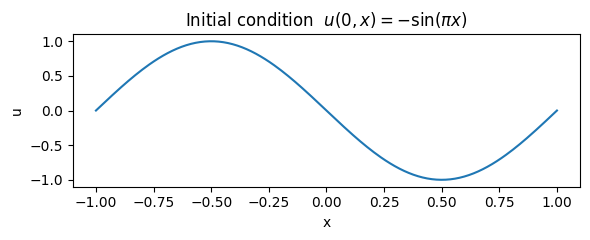

In [7]:
# IC: u(0, x) = -sin(π x)
x_ic = torch.linspace(-1.0, 1.0, 200).unsqueeze(1)   # (200, 1)
u_ic = -torch.sin(np.pi * x_ic)                       # (200, 1)

# BC: u(t, -1) = u(t, 1) = 0
x_bc = torch.tensor([[-1.0], [1.0]])                   # (2, 1)
u_bc = torch.zeros(2, 1)                               # (2, 1)

plt.figure(figsize=(6, 2.5))
plt.plot(x_ic.numpy(), u_ic.numpy())
plt.title('Initial condition  $u(0,x) = -\\sin(\\pi x)$')
plt.xlabel('x'); plt.ylabel('u')
plt.tight_layout()
plt.show()

## 6. Train

`trainer.fit` returns a **list of networks** (one per time level) for TD-PINNs,
or a **single network** for Vanilla.  
PDE constants (`nu`) are passed as keyword arguments and forwarded directly to the residual function.

In [10]:
T   = 0.4
nu  = 0.01 / np.pi

trained_nets = trainer.fit(
    x_ic=x_ic,
    u_ic=u_ic,
    x_bc=x_bc,
    u_bc=u_bc,
    T=T,
    nu=nu,     # forwarded to burgers_residual_td as **pde_kwargs
)

=== TD-PINNs | step 0 — initial condition ===
  [step 0 / IC] epoch   500 | loss 1.3181e-04
  [step 0 / IC] converged at epoch 548 | loss 9.9523e-05
=== TD-PINNs | step 1/4  (t = 0.1) ===
  [step 1] epoch   500 | loss 7.3646e-04
  [step 1] epoch  1000 | loss 2.8402e-04
  [step 1] converged at epoch 1143 | loss 9.0683e-05
=== TD-PINNs | step 2/4  (t = 0.2) ===
  [step 2] epoch   500 | loss 1.9837e-03
  [step 2] epoch  1000 | loss 9.3579e-04
  [step 2] converged at epoch 1375 | loss 8.5362e-05
=== TD-PINNs | step 3/4  (t = 0.3) ===
  [step 3] epoch   500 | loss 1.3085e-02
  [step 3] epoch  1000 | loss 3.1290e-03
  [step 3] epoch  1500 | loss 1.4255e-03
  [step 3] epoch  2000 | loss 2.6214e-04
  [step 3] converged at epoch 2422 | loss 9.0205e-05
=== TD-PINNs | step 4/4  (t = 0.4) ===
  [step 4] epoch   500 | loss 1.0077e-01
  [step 4] epoch  1000 | loss 1.2025e-02
  [step 4] epoch  1500 | loss 1.5536e-02
  [step 4] epoch  2000 | loss 6.0246e-03
  [step 4] epoch  2500 | loss 7.7249e-04
  [

## 7. Evaluate & Plot

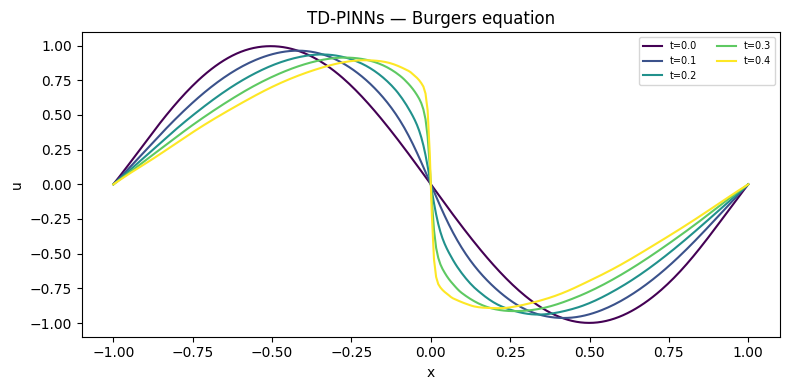

In [11]:
dev    = trainer.device
x_eval = torch.linspace(-1.0, 1.0, 300).unsqueeze(1).to(dev)
dt     = trainer.dt

fig, ax = plt.subplots(figsize=(8, 4))

cmap   = plt.cm.viridis
n_nets = len(trained_nets)

for i, net_i in enumerate(trained_nets):
    net_i.eval()
    with torch.no_grad():
        u_pred = net_i(x_eval).cpu().numpy()
    color = cmap(i / max(n_nets - 1, 1))
    ax.plot(x_eval.cpu().numpy(), u_pred, color=color, label=f't={i*dt:.1f}')

ax.set_xlabel('x')
ax.set_ylabel('u')
ax.set_title('TD-PINNs — Burgers equation')
ax.legend(loc='upper right', fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

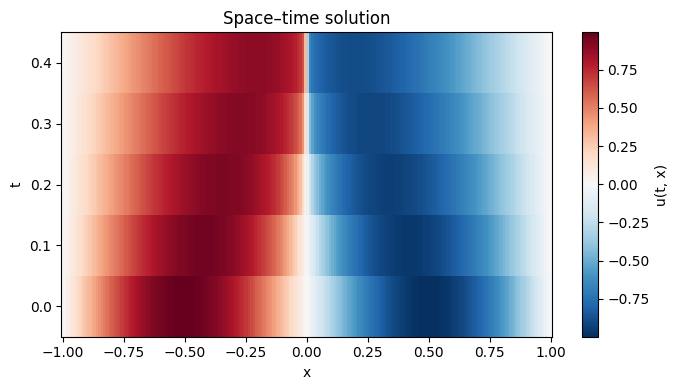

In [12]:
# Space-time heatmap
x_plot = torch.linspace(-1.0, 1.0, 200).unsqueeze(1).to(dev)
U = []
for net_i in trained_nets:
    net_i.eval()
    with torch.no_grad():
        U.append(net_i(x_plot).cpu().numpy().squeeze())

U    = np.array(U)   # (n_steps+1, 200)
t_ax = np.linspace(0, T, n_nets)
x_ax = x_plot.cpu().numpy().squeeze()

fig, ax = plt.subplots(figsize=(7, 4))
pcm = ax.pcolormesh(x_ax, t_ax, U, cmap='RdBu_r', shading='auto')
plt.colorbar(pcm, ax=ax, label='u(t, x)')
ax.set_xlabel('x')
ax.set_ylabel('t')
ax.set_title('Space–time solution')
plt.tight_layout()
plt.show()

## 8. Switching to KAN — one line change

Because `PINArchitecture` returns a plain `nn.Module`, and `torch.autograd.grad`
works on any differentiable `nn.Module`, **nothing else changes**.

```python
# Install once:
# pip install pykan

net_kan = PINArchitecture(
    arch="KAN",
    params_arch={"layers": (1, 16, 16, 1), "grid_size": 5, "spline_order": 3},
)

trainer_kan = PINTrainer(
    net=net_kan,
    scheme="TD-PINNS",
    loss_fn=loss_fn,      # same loss function!
    spatial_dims=[x_dim], # same spatial dimension!
    epochs=3000,
    dt=0.1,
    lr=1e-2,
    tolerance=1e-4,
)

trained_nets_kan = trainer_kan.fit(x_ic, u_ic, x_bc, u_bc, T=T, nu=nu)
```

## 9. Switching to Vanilla PINNs — two line changes

1. The network needs one extra input dimension (t is prepended by the trainer).
2. The residual function uses `du/dt` via autograd instead of the finite-difference `(u − u_prev)/dt`.

`trainer.fit` **always returns `list[nn.Module]`** regardless of scheme:
- TD-PINNs → N+1 elements (index 0 = IC network)
- Vanilla   → 1-element list containing the full (t, x) network

```python
net_v = PINArchitecture(
    arch="MLP",
    params_arch={"layers": (2, 64, 64, 64, 1)},  # 2 = t + x
)

def burgers_residual_vanilla(u, t, x, nu):
    du_dt  = torch.autograd.grad(u.sum(),     t, create_graph=True)[0]
    du_dx  = torch.autograd.grad(u.sum(),     x, create_graph=True)[0]
    du_dxx = torch.autograd.grad(du_dx.sum(), x, create_graph=True)[0]
    return du_dt + u * du_dx - nu * du_dxx

loss_fn_v = PINLossFunction([x_dim], burgers_residual_vanilla)

trainer_v = PINTrainer(
    net=net_v,
    scheme="VANILLA",     # ← the only structural change
    loss_fn=loss_fn_v,
    spatial_dims=[x_dim],
    epochs=10000,
    lr=1e-3,
    tolerance=1e-5,
)

trained_nets_v = trainer_v.fit(x_ic, u_ic, x_bc, u_bc, T=T, nu=nu)
net_v_trained  = trained_nets_v[0]   # the single space-time network
```

## 10. Saving & Loading Trained Networks

`save_pinns` stores all state dicts **plus** the metadata needed to reconstruct any architecture (MLP or KAN) and scheme (TD-PINNs or Vanilla) from a single `.pt` file.

Two dedicated loaders keep the interface explicit:
- `load_tdpinns(path)` → `list[nn.Module]` — one network per time step
- `load_vanilla(path)` → `nn.Module` — the full space-time network

Both raise a clear `ValueError` if you call the wrong loader for a checkpoint.

In [13]:
from pinns_framework import save_pinns, load_pinns

# ── Save (works for any scheme × arch combination) ───────────────────────────
SAVE_PATH   = "burgers_tdpinns_mlp.pt"
ARCH        = "MLP"
PARAMS_ARCH = {"layers": (1, 64, 64, 64, 1), "activation": "tanh"}

save_pinns(trained_nets, trainer, ARCH, PARAMS_ARCH, SAVE_PATH)

# ── Load — scheme detection is automatic ─────────────────────────────────────
# Always returns list[nn.Module]:
#   TD-PINNs → one network per time step  (trained_nets[i] for time i)
#   Vanilla  → one-element list            (trained_nets[0] is the full net)
loaded_nets = load_pinns(SAVE_PATH)

# ── Round-trip verification ───────────────────────────────────────────────────
x_check = torch.linspace(-1.0, 1.0, 5).unsqueeze(1)
with torch.no_grad():
    orig     = trained_nets[0](x_check).numpy()
    reloaded = loaded_nets[0](x_check).numpy()

print("Round-trip outputs match:", np.allclose(orig, reloaded))


Saved 5 network(s) [MLP / TD-PINNs] → 'burgers_tdpinns_mlp.pt'


RuntimeError: Error(s) in loading state_dict for MLP:
	Missing key(s) in state_dict: "net.0.weight", "net.0.bias", "net.2.weight", "net.2.bias", "net.4.weight", "net.4.bias", "net.6.weight", "net.6.bias". 
	Unexpected key(s) in state_dict: "net.node_bias_0", "net.node_scale_0", "net.subnode_bias_0", "net.subnode_scale_0", "net.node_bias_1", "net.node_scale_1", "net.subnode_bias_1", "net.subnode_scale_1", "net.act_fun.0.grid", "net.act_fun.0.coef", "net.act_fun.0.mask", "net.act_fun.0.scale_base", "net.act_fun.0.scale_sp", "net.act_fun.1.grid", "net.act_fun.1.coef", "net.act_fun.1.mask", "net.act_fun.1.scale_base", "net.act_fun.1.scale_sp", "net.symbolic_fun.0.mask", "net.symbolic_fun.0.affine", "net.symbolic_fun.1.mask", "net.symbolic_fun.1.affine". 

## 11. KAN Network Visualization

pykan's `plot()`, `get_act()`, and `prune()` require all internal tensors
on the same device.  When training runs on MPS or CUDA the network weights
end up on that device while some pykan buffers stay on CPU, causing a
`RuntimeError`.

`_kan_cpu(kan_net, x)` deep-copies the inner PyKAN model to CPU and
re-populates its activation caches with a fresh forward pass — making
every pykan introspection call safe regardless of the training device.

In [14]:
import copy

def _kan_cpu(kan_net, x_1d):
    """
    Return (model, x_cpu):
      model  — deep-copied PyKAN model on CPU with activation caches filled
      x_cpu  — the evaluation tensor used to populate the caches

    Works whether the KANNet was trained on CPU, MPS, or CUDA.
    """
    model = copy.deepcopy(kan_net.net).cpu()
    x_cpu = x_1d.detach().cpu().reshape(-1, 1)
    with torch.no_grad():
        model(x_cpu)      # forward — sets cache_data and act_fun internals
    model.get_act(x_cpu)  # computes node_scores, edge_actscale, acts
    return model, x_cpu


def plot_kan_step(trained_nets, step, x_domain, dt, n_vis=300,
                  prune=False, node_th=1e-2, edge_th=1e-2, beta=3):
    """
    Visualize the KAN at one time step.

    prune=True  — show the pruned graph (low-importance neurons removed).
                  Falls back to the unpruned graph if pruning fails.
    beta        — controls smoothness of displayed activation curves.
    """
    lo, hi = x_domain
    x_vis  = torch.linspace(lo, hi, n_vis).unsqueeze(1)
    kan, x_cpu = _kan_cpu(trained_nets[step], x_vis)

    tag = ''
    if prune:
        try:
            kan = kan.prune(node_th=node_th, edge_th=edge_th)
            with torch.no_grad():
                kan(x_cpu)
            kan.get_act(x_cpu)
            tag = ' [pruned]'
        except Exception as exc:
            print(f'  step {step}: pruning skipped — {exc}')
            tag = ' [prune failed — showing unpruned]'

    kan.plot(beta=beta, in_vars=['x'], out_vars=['u'])
    plt.suptitle(
        f'KAN  step {step}   t = {step * dt:.3f}{tag}',
        fontsize=11, y=1.02,
    )
    plt.tight_layout()
    plt.show()
    return kan


/var/folders/wy/ljbyn3qd58nggnt6rcf6d5vr0000gp/T/ipykernel_76287/3480556276.py:49: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


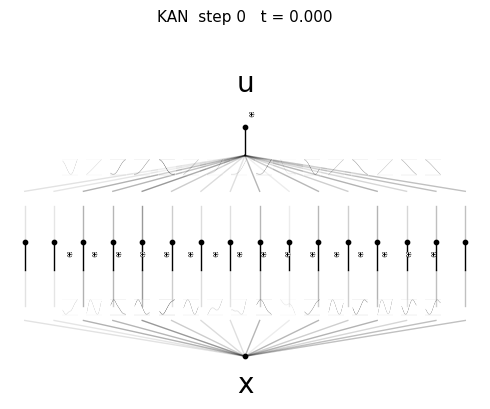

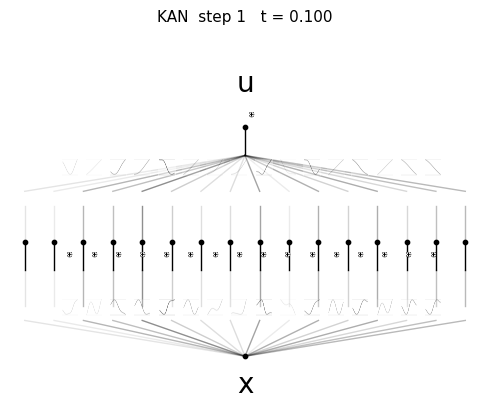

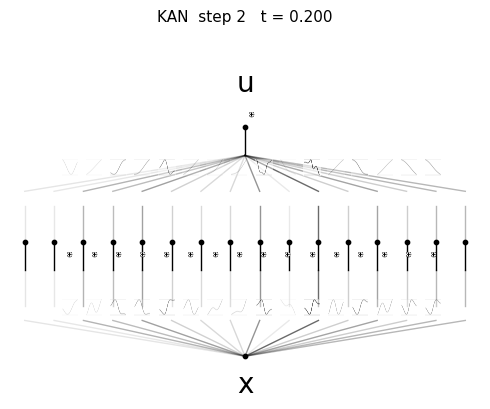

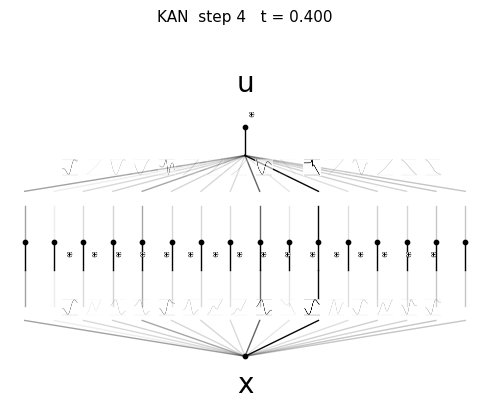

In [15]:
x_domain = (float(x_dim.domain[0]), float(x_dim.domain[1]))

# Pick a few representative time steps to inspect
n_nets = len(trained_nets)
show_steps = sorted({0, 1, n_nets // 2, n_nets - 1})

for step in show_steps:
    plot_kan_step(trained_nets, step, x_domain, dt=trainer.dt)

saving model version 0.1


/var/folders/wy/ljbyn3qd58nggnt6rcf6d5vr0000gp/T/ipykernel_76287/3480556276.py:49: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


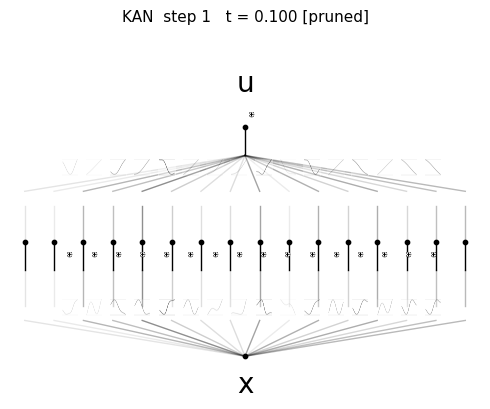

saving model version 0.1


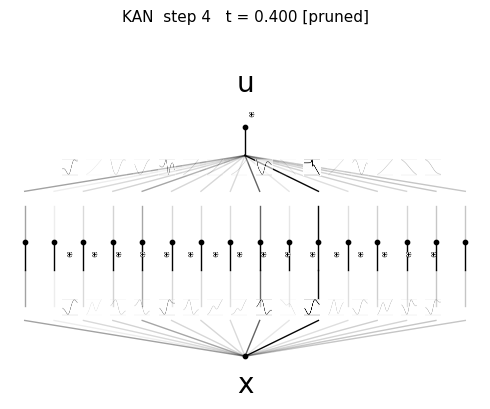

In [16]:
# Pruned view — removes low-importance neurons to see the dominant structure.
# Falls back gracefully if pykan can't prune a particular step.
for step in [1, n_nets - 1]:
    plot_kan_step(trained_nets, step, x_domain, dt=trainer.dt,
                  prune=True, node_th=1e-2, edge_th=1e-2)